In [4]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt
import os
os.environ.pop("PROJ_LIB", None)
os.environ.pop("PROJ_DATA", None)


In [11]:
# Przygotuj 4 zestawy próbek z DEM Kotliny Kłodzkiej: 3 losowe próbki, 30, 300 i 3000.
# Następnie dla każdego zbioru oblicz średnią wysokość. 
# Porównaj ją ze średnią wysokością całego zbioru.

path_to_files = "C:/Users/julia/Desktop/SDG/cwiczenia/dane/"

with rasterio.open(path_to_files + "DEM_kotlina_klodzka.tif") as src:
    dem = src.read(masked = True)

#Przygotuj 4 zestawy próbek z DEM Kotliny Kłodzkiej: 3 losowe próbki, 30, 300 i 3000
probka1 = dem[0][np.random.randint(0, dem.shape[1], 3), np.random.randint(0, dem.shape[2], 3)]
probka2 = dem[0][np.random.randint(0, dem.shape[1], 30), np.random.randint(0, dem.shape[2], 30)]
probka3 = dem[0][np.random.randint(0, dem.shape[1], 300), np.random.randint(0, dem.shape[2], 300)]
probka4 = dem[0][np.random.randint(0, dem.shape[1], 3000), np.random.randint(0, dem.shape[2], 3000)]

print(probka1)
print(probka2)
print(probka3)
print(probka4)

[566.9309692382812 581.9988403320312 219.91607666015625]
[292.716796875 315.8973388671875 572.9273071289062 676.5466918945312
 566.3046264648438 319.2597351074219 216.23117065429688 664.6400756835938
 305.4886779785156 476.0424499511719 277.8119201660156 176.21778869628906
 350.5113830566406 959.0639038085938 275.49798583984375 251.94558715820312
 750.4578247070312 298.4188537597656 405.11474609375 370.2535705566406
 491.06787109375 520.1326904296875 196.33071899414062 627.3279418945312
 625.0203247070312 413.06549072265625 880.2996215820312 315.73468017578125
 267.68548583984375 472.84259033203125]
[689.4498291015625 596.0026245117188 293.40728759765625 349.04345703125
 410.3332214355469 875.8065795898438 827.7197265625 519.4246826171875
 885.2167358398438 383.87286376953125 304.2701416015625 268.33197021484375
 301.58642578125 929.3438720703125 503.0239562988281 150.34669494628906
 251.8096466064453 147.04307556152344 455.3819580078125 363.3673400878906
 378.21478271484375 555.486999

(198, 122, 4)


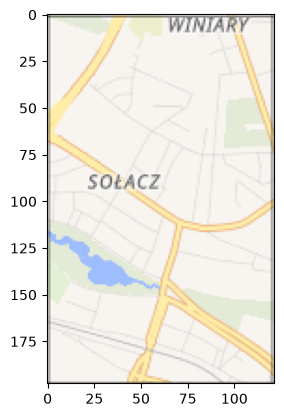

0.00013661202185794486
0.0
16.9
0.0
-8.41750841750794e-05
52.43333333333333


c:\Users\julia\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\rasterio\__init__.py:379: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


In [8]:
# Wykorzystując narzędzie nałożenia siatki na https://mapgridder.com/map zrób zrzut ekranu dowolnego obszaru na ziemi 
# a następnie dokonaj jego georeferencji i wyświetl w QGIS.

from PIL import Image
from rasterio.transform import from_bounds
path_to_files = "C:/Users/julia/Desktop/SDG/cwiczenia/dane/"

# Na początek załadujmy nasz .png i zobaczmy jak wygląda.

image = np.array(Image.open(path_to_files+"solacz.png"))
print(image.shape) # Czego się z tego dowiadujemy?

plt.imshow(image)
plt.show()

# Teraz zmieńmy go w pełnoprawne dane GIS:
with rasterio.open(path_to_files+"solacz.png") as src:
    image = src.read()

    # Zachowujemy tylko kanały RGB
    image = image[:3]

    height = src.height
    width = src.width

    left = 16 + 54/60
    bottom = 52 + 25/60
    right = 16 + 55/60
    top = 52 + 26/60

    transform = from_bounds(
        left,
        bottom,
        right,
        top,
        width,
        height
    )

    print(transform.a)
    print(transform.b)
    print(transform.c)
    print(transform.d)
    print(transform.e)
    print(transform.f)

with rasterio.open(
    "solacz_georef.tif",
    "w",
    driver="GTiff",
    height=height,
    width=width,
    count=3,
    dtype=image.dtype,
    crs="EPSG:4326",
    transform=transform
) as dst:
    dst.write(image)